Saving Cast_Iron_Brake_Block_ML_Ready_Dataset.xlsx to Cast_Iron_Brake_Block_ML_Ready_Dataset (12).xlsx
Dataset dimensions: (170, 5)
Total observations: 170

CALIBRATION PERFORMANCE
--------------------------------
R2   : 0.990005
MAE  : 0.005438
RMSE : 0.006881

REGRESSION INTERCEPT
0.4556154782775924

REGRESSION COEFFICIENTS


,Polynomial Term,Coefficient
0,Brake load (kN),-2.624345e-03
1,Tread speed (km/h),-8.497606e-04
2,Initial braking speed (km/h),-8.328495e-04
3,Speed reduction (km/h),2.053143e-04
4,Brake load (kN)^2,-2.061890e-05
...,...,...
64,Initial braking speed (km/h)^4,1.000000e-10
65,Initial braking speed (km/h)^3 Speed reduction...,1.000000e-10
66,Initial braking speed (km/h)^2 Speed reduction...,1.000000e-10
67,Initial braking speed (km/h) Speed reduction (...,1.000000e-10



COMPLETE REGRESSION EQUATION
--------------------------------
μb = 0.455615478278 - 0.00262434541118(Brake load (kN)) - 0.00084976062869(Tread speed (km/h)) - 0.000832849538684(Initial braking speed (km/h)) + 0.000205314323339(Speed reduction (km/h)) - 2.0618901032e-05(Brake load (kN)^2) - 1.73721855143e-05(Brake load (kN) Tread speed (km/h)) - 1.05112916062e-05(Brake load (kN) Initial braking speed (km/h)) + 7.0002213576e-06(Brake load (kN) Speed reduction (km/h)) + 2.13851174947e-07(Tread speed (km/h)^2) - 2.35910310046e-06(Tread speed (km/h) Initial braking speed (km/h)) - 2.82981616627e-05(Tread speed (km/h) Speed reduction (km/h)) - 3.37807665444e-06(Initial braking speed (km/h)^2) - 2.30006741121e-06(Initial braking speed (km/h) Speed reduction (km/h)) - 1.84297529142e-07(Speed reduction (km/h)^2) + 4.51899786053e-08(Brake load (kN)^3) - 2.13814097794e-07(Brake load (kN)^2 Tread speed (km/h)) - 1.83634510438e-08(Brake load (kN)^2 Initial braking speed (km/h)) + 1.65463130127e-07

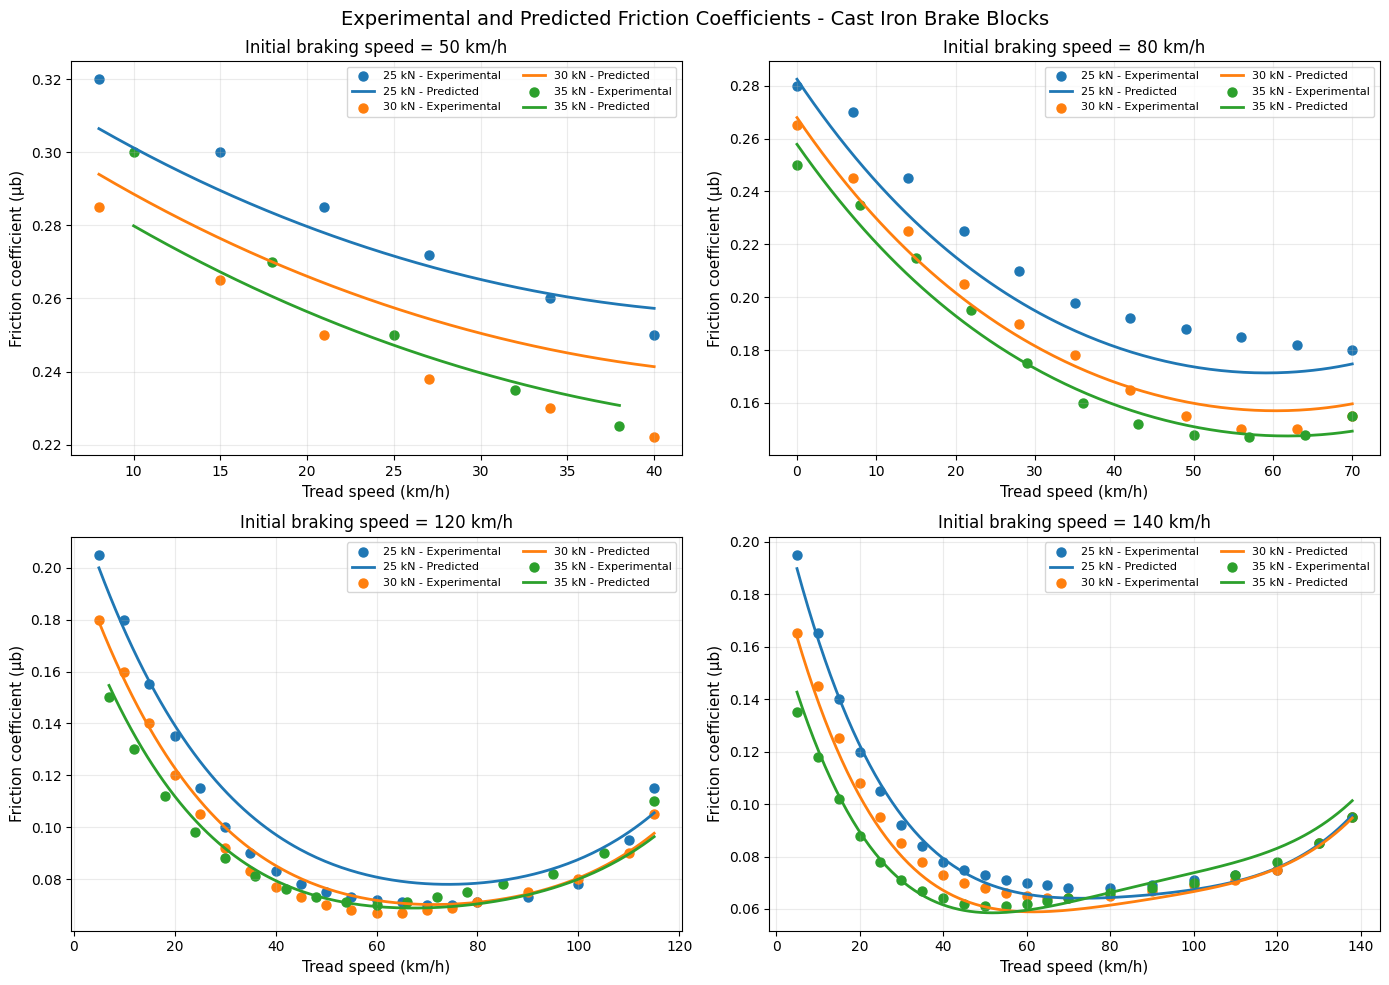


All calculations completed successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ============================================================
# 2. UPLOAD AND READ EXCEL DATASET
# ============================================================

uploaded = files.upload()

file_name = "Cast_Iron_Brake_Block_ML_Ready_Dataset.xlsx"

data = pd.read_excel(
    file_name,
    sheet_name="ML_Ready_Data"
)

# Calculate speed reduction
data["Speed reduction (km/h)"] = (
    data["Initial braking speed (km/h)"]
    - data["Tread speed (km/h)"]
)

# Define four input variables
features = [
    "Brake load (kN)",
    "Tread speed (km/h)",
    "Initial braking speed (km/h)",
    "Speed reduction (km/h)"
]

X = data[features]
y = data["Friction coefficient (μb)"]

print("Dataset dimensions:", data.shape)
print("Total observations:", len(data))

# ============================================================
# 3. DEVELOP FOURTH-DEGREE POLYNOMIAL RIDGE MODEL
# ============================================================

calibration_model = Pipeline([
    ("polynomial", PolynomialFeatures(
        degree=4,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("regression", Ridge(alpha=1.0))
])

# Train using all observations
calibration_model.fit(X, y)

# Predict friction coefficients
y_pred = calibration_model.predict(X)

# ============================================================
# 4. CALCULATE CALIBRATION PERFORMANCE
# ============================================================

r2 = r2_score(y, y_pred)
mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

print("\nCALIBRATION PERFORMANCE")
print("--------------------------------")
print("R2   :", round(r2, 6))
print("MAE  :", round(mae, 6))
print("RMSE :", round(rmse, 6))

# ============================================================
# 5. EXTRACT REGRESSION EQUATION
# ============================================================

poly = calibration_model.named_steps["polynomial"]
scaler = calibration_model.named_steps["scaler"]
ridge = calibration_model.named_steps["regression"]

# Obtain polynomial terms
term_names = poly.get_feature_names_out(features)

# Convert coefficients into original input units
original_coefficients = ridge.coef_ / scaler.scale_

# Correct the intercept
original_intercept = (
    ridge.intercept_
    - np.sum(
        ridge.coef_ * scaler.mean_ / scaler.scale_
    )
)

# Create coefficient table
equation_table = pd.DataFrame({
    "Polynomial Term": term_names,
    "Coefficient": original_coefficients
})

# Display regression intercept
print("\nREGRESSION INTERCEPT")
print(original_intercept)

# Display coefficients
print("\nREGRESSION COEFFICIENTS")
display(equation_table.round(10))

# ============================================================
# 6. PRINT COMPLETE REGRESSION EQUATION
# ============================================================

equation = f"μb = {original_intercept:.12g}"

for term, coef in zip(
    term_names,
    original_coefficients
):

    if abs(coef) > 1e-12:

        sign = "+" if coef >= 0 else "-"

        equation += (
            f" {sign} {abs(coef):.12g}({term})"
        )

print("\nCOMPLETE REGRESSION EQUATION")
print("--------------------------------")
print(equation)

# ============================================================
# 7. PLOT EXPERIMENTAL AND PREDICTED RESULTS
# ============================================================

initial_speeds = [50, 80, 120, 140]
brake_loads = [25, 30, 35]

colors = {
    25: "tab:blue",
    30: "tab:orange",
    35: "tab:green"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, initial_speed in zip(axes, initial_speeds):

    for load in brake_loads:

        subset = data[
            (data["Initial braking speed (km/h)"] == initial_speed) &
            (data["Brake load (kN)"] == load)
        ].sort_values("Tread speed (km/h)")

        if subset.empty:
            continue

        # Experimental observations
        ax.scatter(
            subset["Tread speed (km/h)"],
            subset["Friction coefficient (μb)"],
            color=colors[load],
            marker="o",
            s=42,
            label=f"{load} kN - Experimental"
        )

        # Generate smooth tread-speed values
        speed_grid = np.linspace(
            subset["Tread speed (km/h)"].min(),
            subset["Tread speed (km/h)"].max(),
            200
        )

        # Prepare prediction dataset
        prediction_data = pd.DataFrame({
            "Brake load (kN)": load,
            "Tread speed (km/h)": speed_grid,
            "Initial braking speed (km/h)": initial_speed,
            "Speed reduction (km/h)": initial_speed - speed_grid
        })

        # Predict friction coefficient
        predicted_mu = calibration_model.predict(
            prediction_data[features]
        )

        # Plot predicted curves
        ax.plot(
            speed_grid,
            predicted_mu,
            color=colors[load],
            linewidth=2,
            label=f"{load} kN - Predicted"
        )

    ax.set_title(
        f"Initial braking speed = {initial_speed} km/h",
        fontsize=12
    )

    ax.set_xlabel("Tread speed (km/h)", fontsize=11)
    ax.set_ylabel("Friction coefficient (μb)", fontsize=11)

    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8, ncol=2)

fig.suptitle(
    "Experimental and Predicted Friction Coefficients - Cast Iron Brake Blocks",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "Cast_Iron_Calibration_Figure.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. SAVE REGRESSION EQUATION AND COEFFICIENTS
# ============================================================

# Save intercept and coefficients
intercept_table = pd.DataFrame({
    "Polynomial Term": ["Intercept"],
    "Coefficient": [original_intercept]
})

complete_coefficients = pd.concat(
    [intercept_table, equation_table],
    ignore_index=True
)

# Save calibration predictions
calibration_results = data.copy()

calibration_results["Predicted Friction Coefficient"] = y_pred

calibration_results["Residual"] = (
    calibration_results["Friction coefficient (μb)"]
    - calibration_results["Predicted Friction Coefficient"]
)

# Export all results into one Excel workbook
with pd.ExcelWriter(
    "Cast_Iron_Regression_Results.xlsx",
    engine="openpyxl"
) as writer:

    complete_coefficients.to_excel(
        writer,
        sheet_name="Regression_Coefficients",
        index=False
    )

    calibration_results.to_excel(
        writer,
        sheet_name="Calibration_Predictions",
        index=False
    )

    pd.DataFrame({
        "Metric": ["R2", "MAE", "RMSE"],
        "Value": [r2, mae, rmse]
    }).to_excel(
        writer,
        sheet_name="Model_Performance",
        index=False
    )

# ============================================================
# 9. DOWNLOAD OUTPUT FILES
# ============================================================

print("\nAll calculations completed successfully.")

files.download("Cast_Iron_Regression_Results.xlsx")
files.download("Cast_Iron_Calibration_Figure.png")
